In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats

In [ ]:
import pandas as pd
from google.colab import files

arquivos = files.upload()

Saving student-por.csv to student-por.csv
Saving student-mat.csv to student-mat.csv


In [ ]:
d1 = pd.read_csv('student-por.csv')
d2 = pd.read_csv('student-mat.csv')

In [ ]:
d1 = d1.rename(columns={
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'Medu': 'escolaridade_mae',
    'Fedu': 'escolaridade_pai',
    'Mjob': 'profissao_mae',
    'Fjob': 'profissao_pai',
    'reason': 'motivo_escolha_escola',
    'guardian': 'guardiao_legal',
    'traveltime': 'tempo_deslocamento',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'schoolsup': 'apoio_escola',
    'paid': 'aulas_extras_pagas',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'absences': 'faltas',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final',
})

d2 = d2.rename(columns={
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'Medu': 'escolaridade_mae',
    'Fedu': 'escolaridade_pai',
    'Mjob': 'profissao_mae',
    'Fjob': 'profissao_pai',
    'reason': 'motivo_escolha_escola',
    'guardian': 'guardiao_legal',
    'traveltime': 'tempo_deslocamento',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'schoolsup': 'apoio_escola',
    'paid': 'aulas_extras_pagas',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'absences': 'faltas',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final',
})

In [ ]:
maximo_faltas = d1['faltas'].max()
print(f"O número máximo de faltas é: {maximo_faltas}")

O número máximo de faltas é: 32


In [ ]:
maximo_faltas = d2['faltas'].max()
print(f"O número máximo de faltas é: {maximo_faltas}")

O número máximo de faltas é: 75


In [ ]:
# adicionar coluna com a média das 3 notas de cada aluno
d1["media_notas"] = d1[["nota_1p", "nota_2p", "nota_final"]].mean(axis=1)

display(d1.head())

,school,sexo,idade,regiao,famsize,Pstatus,escolaridade_mae,escolaridade_pai,profissao_mae,profissao_pai,...,tempo_livre,frequencia_saida_com_amigos,consumo_alcool_semana,consumo_alcool_fim_de_semana,estado_saude_atual,faltas,nota_1p,nota_2p,nota_final,media_notas
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,7.333333
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,10.333333
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,12.333333
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,14.000000
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,12.333333


In [ ]:
import pandas as pd
import numpy as np

CORTE_NOTA = 10
LIMIAR = 0.10        # 10% da amplitude

# Q1 = 25% dos alunos com piores notas
# Q4 = 25% dos alunos com melhores notas
q1_mask = d1["media_notas"] <= d1["media_notas"].quantile(0.25)
q4_mask = d1["media_notas"] >= d1["media_notas"].quantile(0.75)

# dataframes apenas com os extremos
d1_q1 = d1[q1_mask]
d1_q4 = d1[q4_mask]

print(f"Total de alunos no Q1 (piores): {len(d1_q1)}")
print(f"Total de alunos no Q4 (melhores): {len(d1_q4)}\n")

# variáveis ordinais
numericas_escala = [
    "escolaridade_mae", "escolaridade_pai", "tempo_deslocamento",
    "tempo_semanal_estudo", "nº_reprovacoes", "qualidade_relacao_familiar",
    "tempo_livre", "frequencia_saida_com_amigos", "consumo_alcool_semana",
    "consumo_alcool_fim_de_semana", "estado_saude_atual", "faltas"
]

resultados_escala = []

for var in numericas_escala:
    if var in d1.columns:

        # média dos extremos - q1 e q4
        media_q1 = d1_q1[var].mean()
        media_q4 = d1_q4[var].mean()

        # descobrir o mín e máx para calcular a amplitude da variável
        vmin = d1[var].min()
        vmax = d1[var].max()
        amplitude = vmax - vmin

        # diferença entre as médias dos dois grupos e
        # diferença relativa para comparar variáveis com escalas diferentes
        diff = media_q4 - media_q1
        diff_relativa = abs(diff) / amplitude if amplitude > 0 else 0

        passou = diff_relativa >= LIMIAR

        # dicionário
        resultados_escala.append({
            'Variável': var,
            'Escala': f"{vmin}-{vmax}",
            'Média Q1 (Piores)': round(media_q1, 3),
            'Média Q4 (Melhores)': round(media_q4, 3),
            'Diferença': round(diff, 3),
            'Diff Relativa (%)': f"{diff_relativa*100:.1f}%",
            f'Passou (≥{LIMIAR:.0%})': 'SIM' if passou else 'NÃO'
        })

        # resumo de comparação
        print(f"{var:28s} | Q1={media_q1:5.2f} | Q4={media_q4:5.2f} | diff={diff:5.2f} | rel={diff_relativa*100:5.1f}% -> {'PASSOU' if passou else 'NÃO PASSOU'}")

# mostrar dataframe
print("\n" + "="*60)
df_resultados_escala = pd.DataFrame(resultados_escala)
display(df_resultados_escala)

Total de alunos no Q1 (piores): 199
Total de alunos no Q4 (melhores): 180

escolaridade_mae             | Q1= 2.12 | Q4= 2.96 | diff= 0.83 | rel= 20.9% -> PASSOU
escolaridade_pai             | Q1= 1.93 | Q4= 2.62 | diff= 0.69 | rel= 17.2% -> PASSOU
tempo_deslocamento           | Q1= 1.74 | Q4= 1.42 | diff=-0.33 | rel= 10.9% -> PASSOU
tempo_semanal_estudo         | Q1= 1.66 | Q4= 2.22 | diff= 0.56 | rel= 18.8% -> PASSOU
nº_reprovacoes               | Q1= 0.62 | Q4= 0.02 | diff=-0.60 | rel= 20.0% -> PASSOU
qualidade_relacao_familiar   | Q1= 3.83 | Q4= 4.01 | diff= 0.17 | rel=  4.3% -> NÃO PASSOU
tempo_livre                  | Q1= 3.35 | Q4= 3.10 | diff=-0.25 | rel=  6.3% -> NÃO PASSOU
frequencia_saida_com_amigos  | Q1= 3.34 | Q4= 3.08 | diff=-0.26 | rel=  6.5% -> NÃO PASSOU
consumo_alcool_semana        | Q1= 1.71 | Q4= 1.26 | diff=-0.45 | rel= 11.3% -> PASSOU
consumo_alcool_fim_de_semana | Q1= 2.56 | Q4= 1.98 | diff=-0.58 | rel= 14.5% -> PASSOU
estado_saude_atual           | Q1= 3.59 | Q

,Variável,Escala,Média Q1 (Piores),Média Q4 (Melhores),Diferença,Diff Relativa (%),Passou (≥10%)
0,escolaridade_mae,0-4,2.121,2.956,0.835,20.9%,SIM
1,escolaridade_pai,0-4,1.935,2.622,0.688,17.2%,SIM
2,tempo_deslocamento,1-4,1.744,1.417,-0.327,10.9%,SIM
3,tempo_semanal_estudo,1-4,1.658,2.222,0.564,18.8%,SIM
4,nº_reprovacoes,0-3,0.618,0.017,-0.601,20.0%,SIM
5,qualidade_relacao_familiar,1-5,3.834,4.006,0.171,4.3%,NÃO
6,tempo_livre,1-5,3.352,3.100,-0.252,6.3%,NÃO
7,frequencia_saida_com_amigos,1-5,3.342,3.083,-0.258,6.5%,NÃO
8,consumo_alcool_semana,1-5,1.714,1.261,-0.452,11.3%,SIM
9,consumo_alcool_fim_de_semana,1-5,2.558,1.978,-0.580,14.5%,SIM


# **1. Variáveis que PASSARAM**

* **Aspectos Socioeconômicos e Estruturais:**

 A **escolaridade da mãe (20.9%)** e do **pai (17.2%)** são os maiores separadores. Alunos do Q4 (melhores notas) têm, em média, pais com nível educacional superior. Além disso, o **tempo de deslocamento (10.9%)** é menor para o Q4 (melhores notas), sugerindo que alunos de melhor desempenho talvez morem mais perto da escola ou em regiões com melhor infraestrutura, evitando o desgaste de longos trajetos.

* **Aspectos Acadêmicos e de Esforço:**

O **tempo semanal de estudo (18.8%)** é significativamente maior no Q4 (melhores notas). Mais significante ainda é o **histórico de reprovações (20.0%)**: os alunos do Q1 (piores notas) possuem um histórico de reprovações (média de 0.62), enquanto o Q4 (melhores notas) é composto quase que totalmente por alunos que nunca reprovaram (média de 0.02). Isso mostra que quem reprova, tende a ter mais dificuldade, diferente de quem nunca reprovou.

* **Aspectos de Estilo de Vida:**

O **consumo de álcool**, especialmente no **fim de semana (14.5%)**, é maior no grupo de pior desempenho. Isso indica que hábitos de lazer que envolvem álcool estão correlacionados com a queda de desempenho.

# **2. Variáveis que NÃO PASSARAM**

O rótulo "não passar" **não significa que a variável não seja importante**, mas sim que ela **não serve para diferenciar** os extremos. Ambos os grupos se comportam de forma muito parecida nestes aspectos:

* **Base Emocional e Física:** A **qualidade da relação familiar (4.3%)** e o **estado de saúde (7.3%)** são altos e muito similares em ambos os grupos (médias entre 3.3 e 4.0 em escalas de 5). Isso indica que tanto os alunos que vão muito bem quanto os que vão mal geralmente têm apoio da família e se sentem saudáveis.

* **Vida Social:** A **frequência de saída com amigos (6.5%)** e o **tempo livre (6.3%)** são praticamente idênticos. Isso derruba o mito de que o aluno de nota alta é uma pessoa que não sai de casa. Ambos os grupos socializam, a diferença está na maneira que eles gerenciam o tempo restante como vimos no "tempo semanal de estudo", que foi maior no Q4 (melhores notas).

* **Faltas (5.1%):** Embora o Q1 falte mais (4.43 dias) que o Q4 (2.79 dias), a diferença absoluta é de apenas 1.64 dia. Como a escala de faltas é gigantesca (vai de 0 a 32), essa diferença representa apenas 5.1% da amplitude total. Ou seja, na prática, a quantidade de faltas, embora exista, não é um divisor de tão relevante quanto o histórico de reprovações ou o tempo de estudo.

# **3. Conclusão: O Perfil dos Extremos**

* **Perfil Q4 (Melhores Notas):** Geralmente tem pais com maior escolaridade, mora mais perto da escola, dedica mais horas semanais aos estudos, quase nunca reprovou antes e consome menos álcool nos fins de semana. Sua vida social e saúde são equilibradas.

* **Perfil Q1 (Piores Notas):** Tende a ter pais com menor escolaridade, gasta mais tempo no trânsito, estuda menos horas por semana, carrega um histórico de reprovações anteriores e tem um consumo de álcool (especialmente no fim de semana) mais frequente. Apesar disso, sua saúde, relação familiar e tempo de lazer são semelhantes aos do Q4.

In [ ]:
#eliminando as variáveis
nao_passou = ['qualidade_relacao_familiar', 'tempo_livre', 'frequencia_saida_com_amigos', 'estado_saude_atual', 'faltas']
d1 = d1.drop(columns=nao_passou, axis=1)

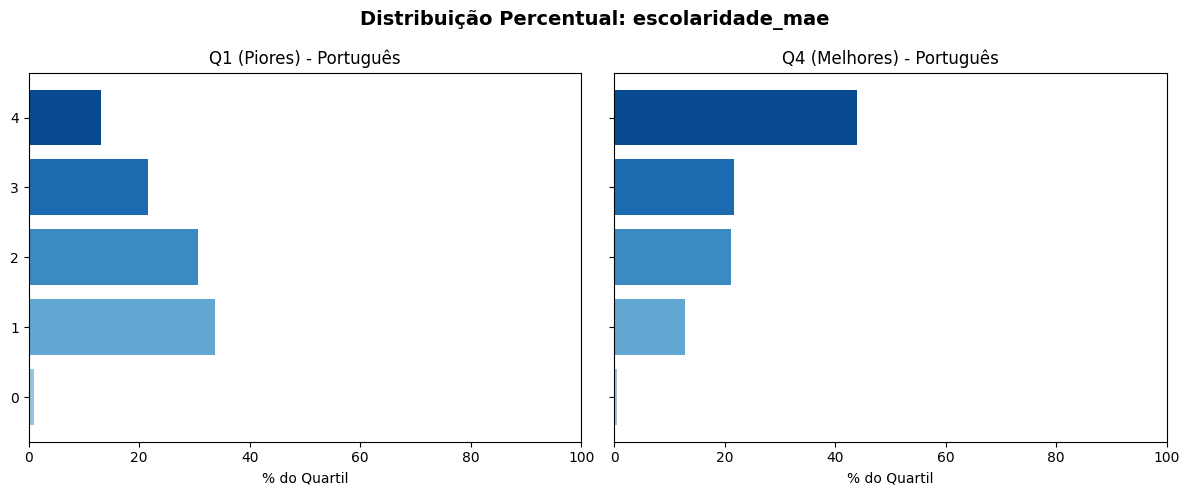

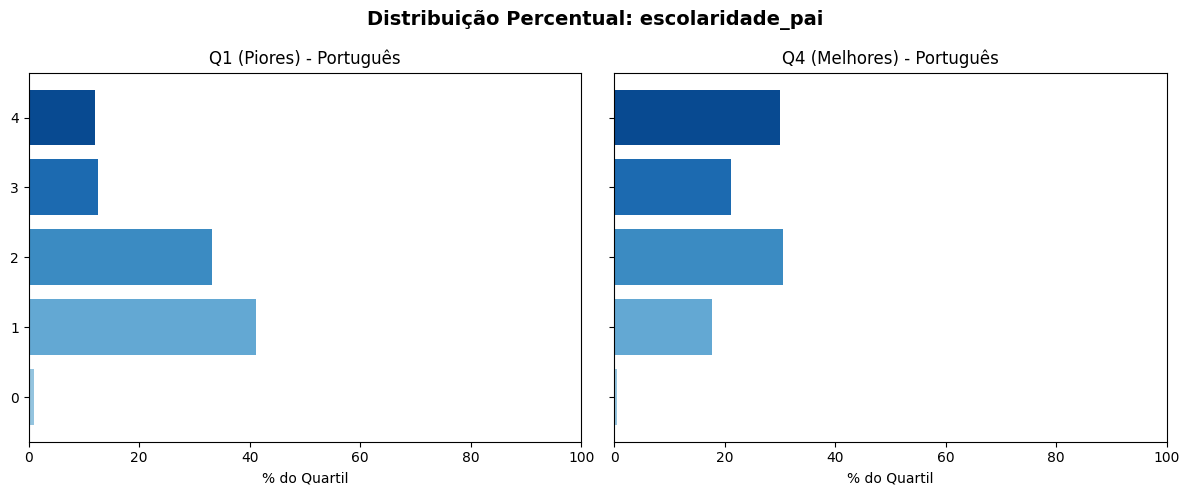

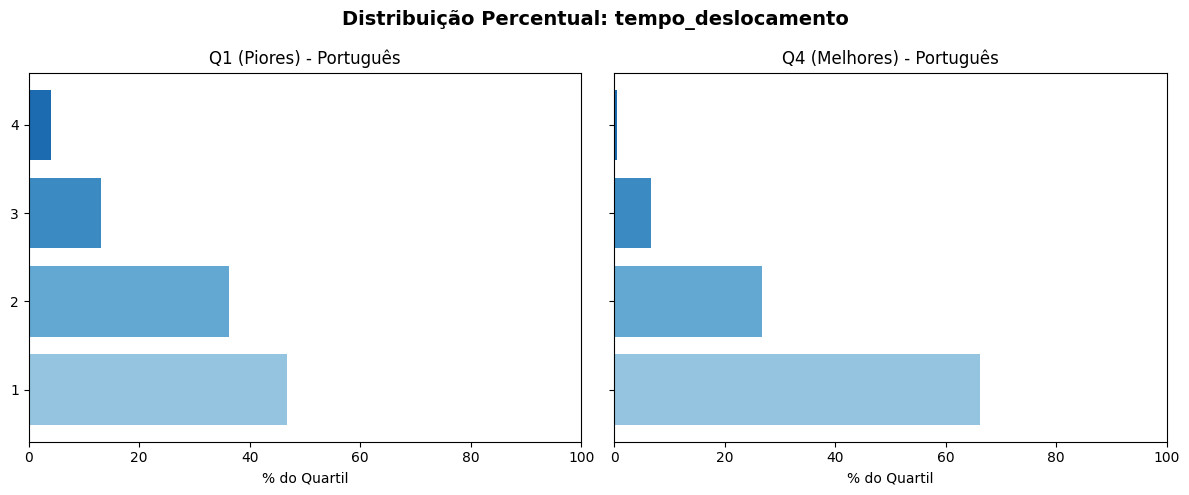

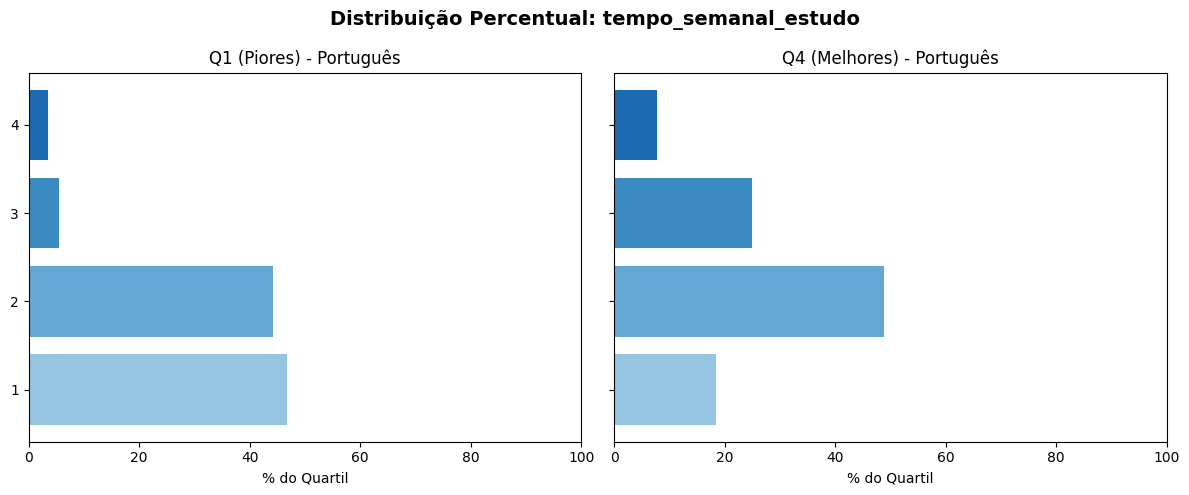

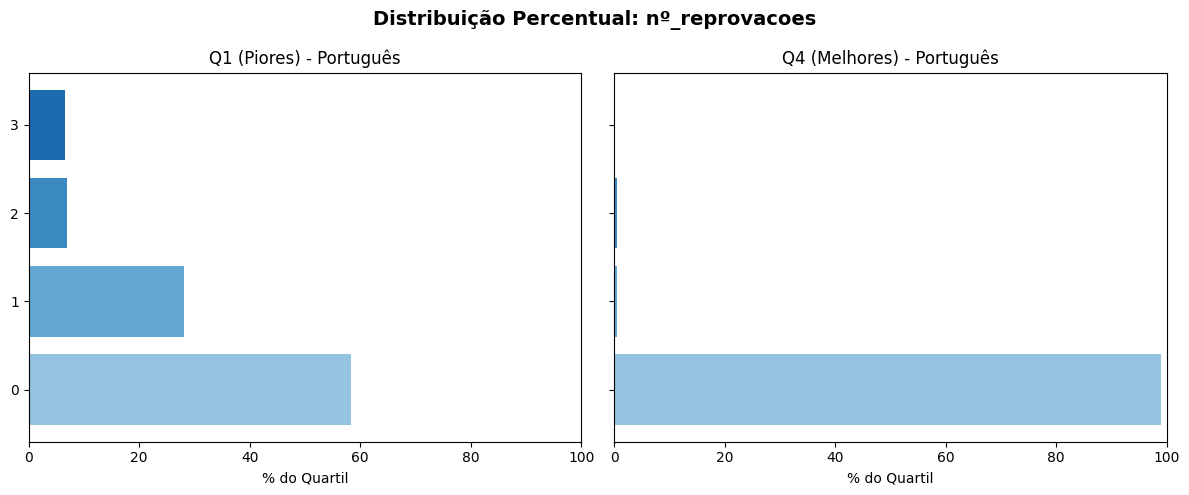

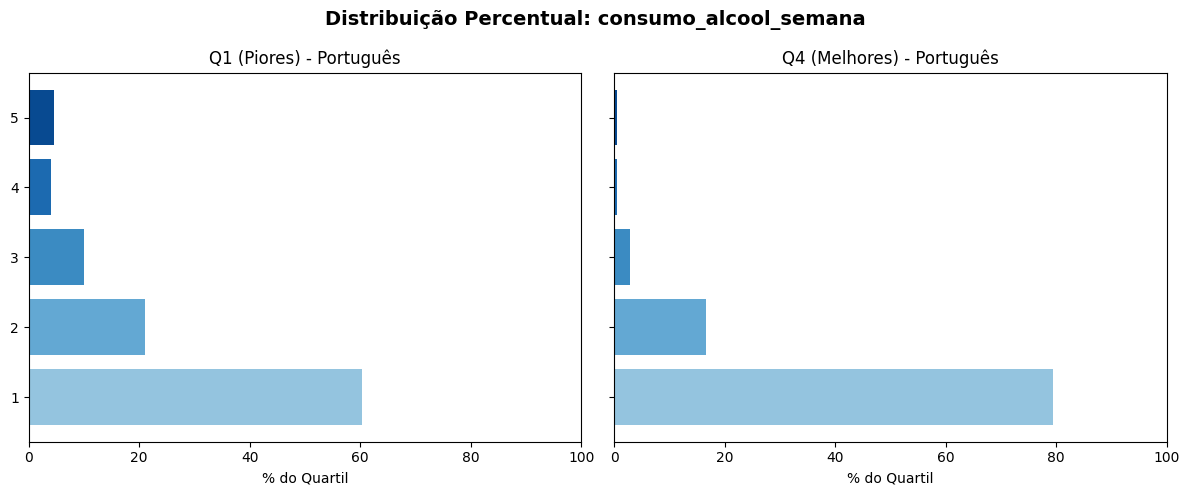

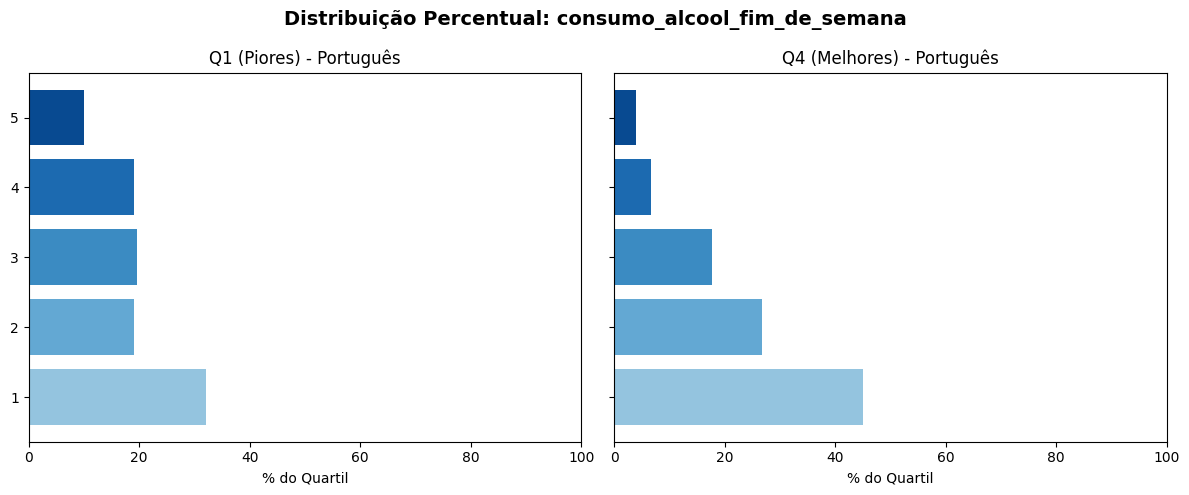

In [22]:
# definindo os quartis
def plotar_empilhado_100(df, nome_dataset, variaveis):
    q1_mask = df["media_notas"] <= df["media_notas"].quantile(0.25)
    q4_mask = df["media_notas"] >= df["media_notas"].quantile(0.75)

    df_q1 = df[q1_mask]
    df_q4 = df[q4_mask]

    cores = plt.cm.Blues(np.linspace(0.4, 0.9, 5))

    for var in variaveis:
        if var not in df.columns:
            continue

        c1 = df_q1[var].value_counts().sort_index()
        c4 = df_q4[var].value_counts().sort_index()
        categorias = sorted(set(c1.index).union(set(c4.index)))

        # pula se tiver muitas categorias (como faltas)
        if len(categorias) > 10:
            continue

        # calcula porcentagens
        perc_q1 = [(c1.get(cat, 0) / len(df_q1) * 100) for cat in categorias]
        perc_q4 = [(c4.get(cat, 0) / len(df_q4) * 100) for cat in categorias]

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

        # Gráfico Q1
        ax1.barh([str(c) for c in categorias], perc_q1, color=cores[:len(categorias)])
        ax1.set_title(f'Q1 (Piores) - {nome_dataset}')
        ax1.set_xlabel('% do Quartil')
        ax1.set_xlim(0, 100)

        # Gráfico Q4
        ax2.barh([str(c) for c in categorias], perc_q4, color=cores[:len(categorias)])
        ax2.set_title(f'Q4 (Melhores) - {nome_dataset}')
        ax2.set_xlabel('% do Quartil')
        ax2.set_xlim(0, 100)

        fig.suptitle(f'Distribuição Percentual: {var}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()


variaveis_analise = [
    "escolaridade_mae", "escolaridade_pai", "tempo_deslocamento",
    "tempo_semanal_estudo", "nº_reprovacoes", "consumo_alcool_semana",
    "consumo_alcool_fim_de_semana"
]


plotar_empilhado_100(d1, "Português", variaveis_analise)

Pergunta: O esforço do aluno (estudar) consegue compensar a falta de escolaridade dos pais?

Pergunta: Beber no fim de semana anula o benefício de estudar durante a semana?

Pergunta: A frequência de beber piora em casos de quem ja tem um histórico de reprovações?

Pergunta: O tempo de deslocamento afeta na quantidade de horas de estudo?

ANÁLISE DE COMBINAÇÕES DE VARIÁVEIS - D1 (PORCENTAGEM)


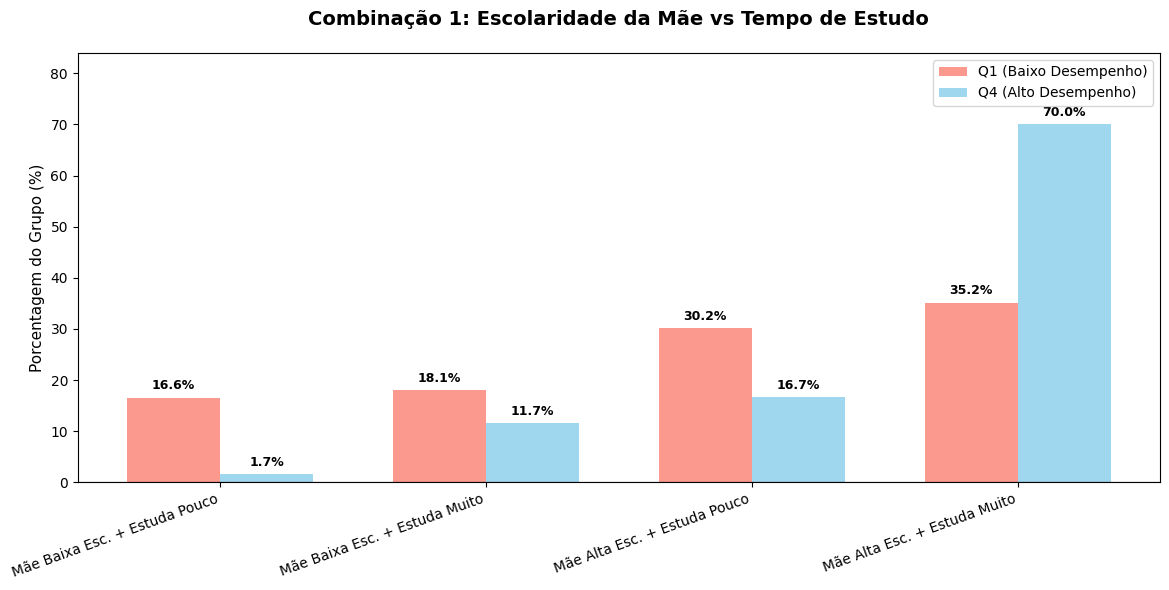

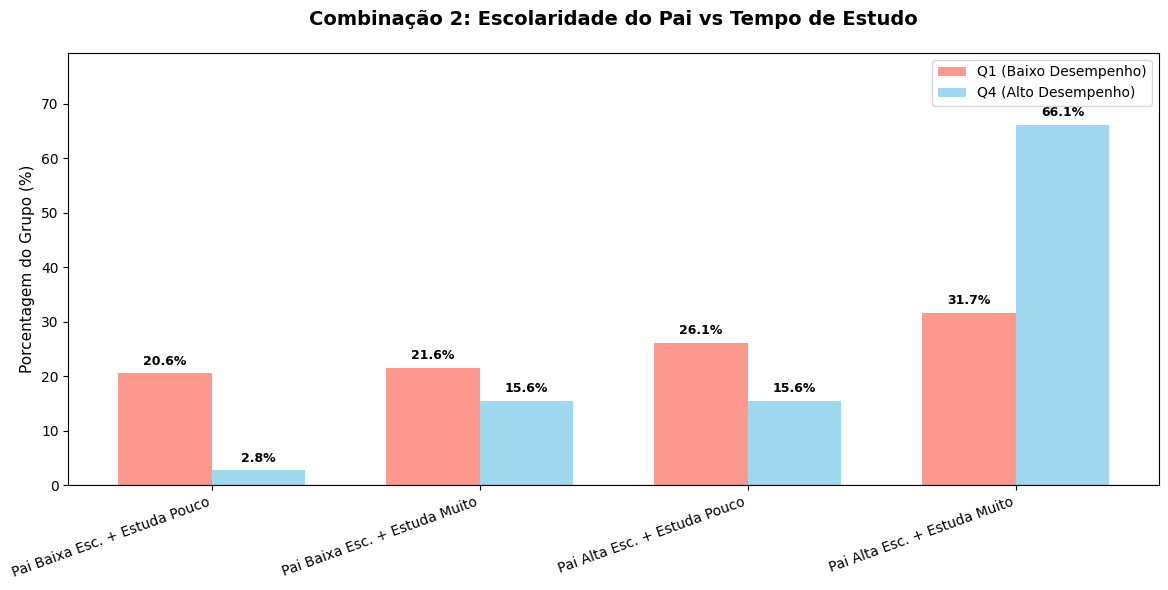

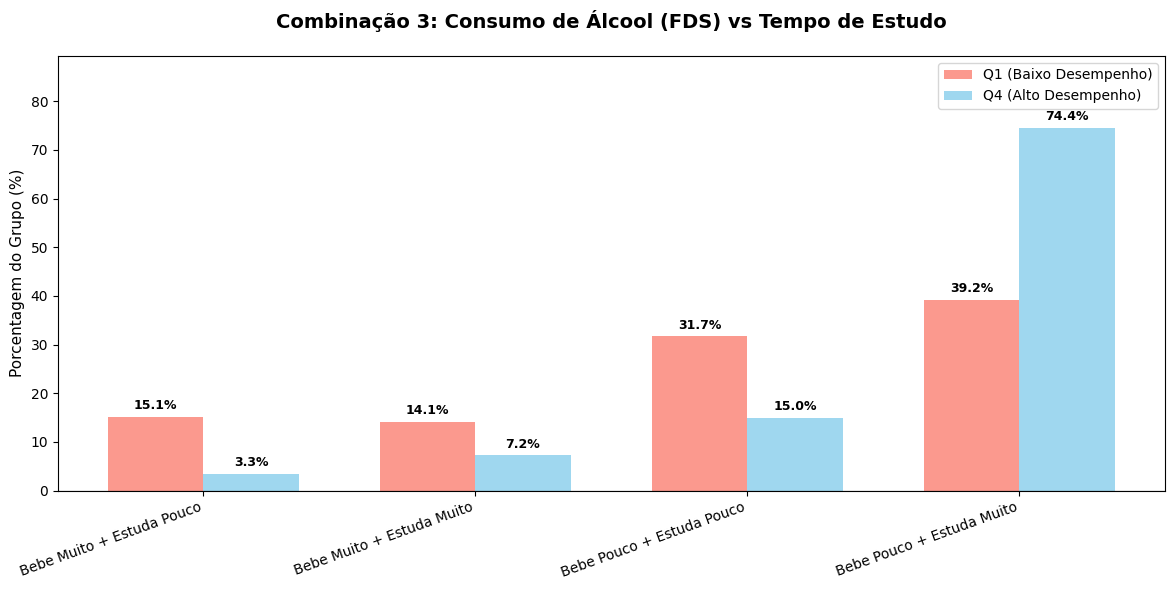

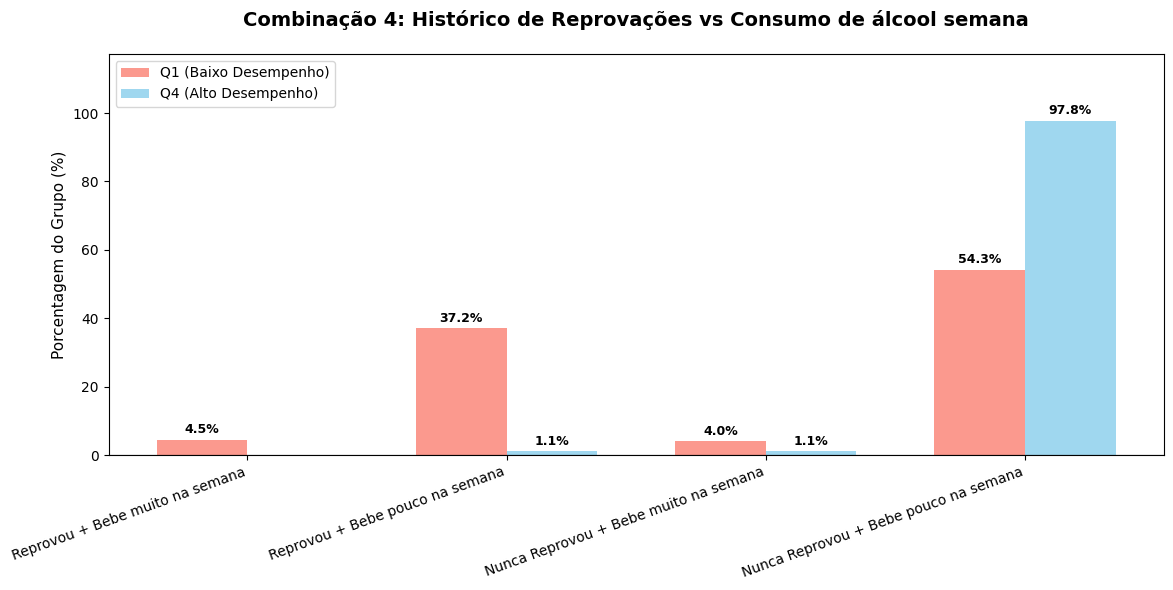

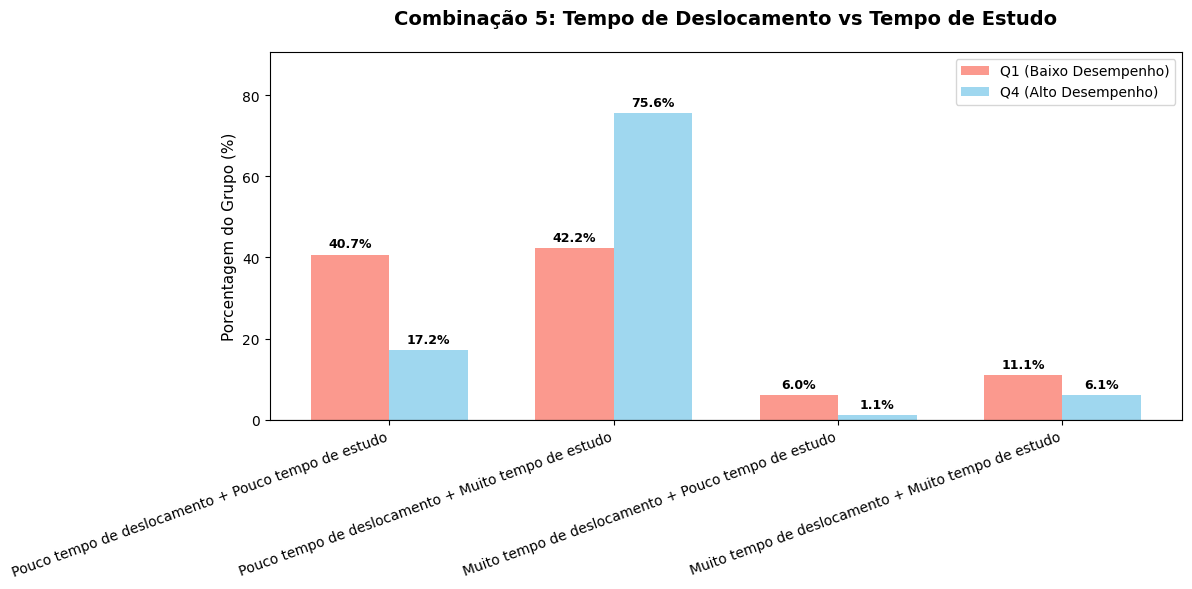

In [32]:
d1_barras = d1.copy()

# cortes para isolar os extremos
q1_corte = d1_barras['media_notas'].quantile(0.25)
q4_corte = d1_barras['media_notas'].quantile(0.75)

d1_barras['desempenho'] = 'Medio'
d1_barras.loc[d1_barras['media_notas'] <= q1_corte, 'desempenho'] = 'Q1_Baixo'
d1_barras.loc[d1_barras['media_notas'] >= q4_corte, 'desempenho'] = 'Q4_Alto'

# Combinação 1: Escolaridade da Mãe + Estudo
d1_barras['perfil_mae_estudo'] = 'Outros'
d1_barras.loc[(d1_barras['escolaridade_mae'] <= 1) & (d1_barras['tempo_semanal_estudo'] <= 1), 'perfil_mae_estudo'] = 'Mãe Baixa Esc. + Estuda Pouco'
d1_barras.loc[(d1_barras['escolaridade_mae'] <= 1) & (d1_barras['tempo_semanal_estudo'] >= 2), 'perfil_mae_estudo'] = 'Mãe Baixa Esc. + Estuda Muito'
d1_barras.loc[(d1_barras['escolaridade_mae'] >= 2) & (d1_barras['tempo_semanal_estudo'] <= 1), 'perfil_mae_estudo'] = 'Mãe Alta Esc. + Estuda Pouco'
d1_barras.loc[(d1_barras['escolaridade_mae'] >= 2) & (d1_barras['tempo_semanal_estudo'] >= 2), 'perfil_mae_estudo'] = 'Mãe Alta Esc. + Estuda Muito'

# Combinação 2: Escolaridade do Pai + Estudo
d1_barras['perfil_pai_estudo'] = 'Outros'
d1_barras.loc[(d1_barras['escolaridade_pai'] <= 1) & (d1_barras['tempo_semanal_estudo'] <= 1), 'perfil_pai_estudo'] = 'Pai Baixa Esc. + Estuda Pouco'
d1_barras.loc[(d1_barras['escolaridade_pai'] <= 1) & (d1_barras['tempo_semanal_estudo'] >= 2), 'perfil_pai_estudo'] = 'Pai Baixa Esc. + Estuda Muito'
d1_barras.loc[(d1_barras['escolaridade_pai'] >= 2) & (d1_barras['tempo_semanal_estudo'] <= 1), 'perfil_pai_estudo'] = 'Pai Alta Esc. + Estuda Pouco'
d1_barras.loc[(d1_barras['escolaridade_pai'] >= 2) & (d1_barras['tempo_semanal_estudo'] >= 2), 'perfil_pai_estudo'] = 'Pai Alta Esc. + Estuda Muito'

# Combinação 2: Álcool FDS + Estudo
d1_barras['perfil_alcool_estudo'] = 'Outros'
d1_barras.loc[(d1_barras['consumo_alcool_fim_de_semana'] >= 4) & (d1_barras['tempo_semanal_estudo'] <= 1), 'perfil_alcool_estudo'] = 'Bebe Muito + Estuda Pouco'
d1_barras.loc[(d1_barras['consumo_alcool_fim_de_semana'] >= 4) & (d1_barras['tempo_semanal_estudo'] >= 2), 'perfil_alcool_estudo'] = 'Bebe Muito + Estuda Muito'
d1_barras.loc[(d1_barras['consumo_alcool_fim_de_semana'] <= 3) & (d1_barras['tempo_semanal_estudo'] <= 1), 'perfil_alcool_estudo'] = 'Bebe Pouco + Estuda Pouco'
d1_barras.loc[(d1_barras['consumo_alcool_fim_de_semana'] <= 3) & (d1_barras['tempo_semanal_estudo'] >= 2), 'perfil_alcool_estudo'] = 'Bebe Pouco + Estuda Muito'

# Reprovações + Álcool na Semana
d1_barras['perfil_reprov_alcool_semana'] = 'Outros'
d1_barras.loc[(d1_barras['nº_reprovacoes'] >= 1) & (d1_barras['consumo_alcool_semana'] >= 4), 'perfil_reprov_alcool_semana'] = 'Reprovou + Bebe muito na semana'
d1_barras.loc[(d1_barras['nº_reprovacoes'] >= 1) & (d1_barras['consumo_alcool_semana'] <= 3), 'perfil_reprov_alcool_semana'] = 'Reprovou + Bebe pouco na semana'
d1_barras.loc[(d1_barras['nº_reprovacoes'] == 0) & (d1_barras['consumo_alcool_semana'] >= 4), 'perfil_reprov_alcool_semana'] = 'Nunca Reprovou + Bebe muito na semana'
d1_barras.loc[(d1_barras['nº_reprovacoes'] == 0) & (d1_barras['consumo_alcool_semana'] <= 3), 'perfil_reprov_alcool_semana'] = 'Nunca Reprovou + Bebe pouco na semana'

# Deslocamento + Horas de estudo
d1_barras['perfil_deslocamento_estudo'] = 'Outros'
d1_barras.loc[(d1_barras['tempo_deslocamento'] <= 2) & (d1_barras['tempo_semanal_estudo'] <= 1), 'perfil_deslocamento_estudo'] = 'Pouco tempo de deslocamento + Pouco tempo de estudo'
d1_barras.loc[(d1_barras['tempo_deslocamento'] <= 2) & (d1_barras['tempo_semanal_estudo'] >= 2), 'perfil_deslocamento_estudo'] = 'Pouco tempo de deslocamento + Muito tempo de estudo'
d1_barras.loc[(d1_barras['tempo_deslocamento'] >= 3) & (d1_barras['tempo_semanal_estudo'] <= 1), 'perfil_deslocamento_estudo'] = 'Muito tempo de deslocamento + Pouco tempo de estudo'
d1_barras.loc[(d1_barras['tempo_deslocamento'] >= 3) & (d1_barras['tempo_semanal_estudo'] >= 2), 'perfil_deslocamento_estudo'] = 'Muito tempo de deslocamento + Muito tempo de estudo'


def plotar_barras_percentual(coluna_combinacao, titulo, ordem_categorias=None):
    df_filtrado = d1_barras[d1_barras['desempenho'].isin(['Q1_Baixo', 'Q4_Alto'])]

    perc_q1 = df_filtrado[df_filtrado['desempenho'] == 'Q1_Baixo'][coluna_combinacao].value_counts(normalize=True) * 100
    perc_q4 = df_filtrado[df_filtrado['desempenho'] == 'Q4_Alto'][coluna_combinacao].value_counts(normalize=True) * 100

    todas_cats = sorted(set(perc_q1.index).union(set(perc_q4.index)))
    if ordem_categorias:
        todas_cats = [c for c in ordem_categorias if c in todas_cats]

    vals_q1 = [perc_q1.get(cat, 0) for cat in todas_cats]
    vals_q4 = [perc_q4.get(cat, 0) for cat in todas_cats]

    x = np.arange(len(todas_cats))
    largura = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - largura/2, vals_q1, largura, label='Q1 (Baixo Desempenho)', color='salmon', alpha=0.8)
    ax.bar(x + largura/2, vals_q4, largura, label='Q4 (Alto Desempenho)', color='skyblue', alpha=0.8)

    for i, (v1, v2) in enumerate(zip(vals_q1, vals_q4)):
        if v1 > 0: ax.text(i - largura/2, v1 + 1, f'{v1:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
        if v2 > 0: ax.text(i + largura/2, v2 + 1, f'{v2:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

    ax.set_ylabel('Porcentagem do Grupo (%)', fontsize=11)
    ax.set_title(titulo, fontsize=14, fontweight='bold', pad=20)
    ax.set_xticks(x)
    ax.set_xticklabels(todas_cats, rotation=20, ha='right', fontsize=10)
    ax.legend(fontsize=10)
    ax.set_ylim(0, max(max(vals_q1), max(vals_q4)) * 1.2)
    ax.axhline(y=0, color='black', linewidth=0.8)

    plt.tight_layout()
    plt.show()

print("ANÁLISE DE COMBINAÇÕES DE VARIÁVEIS - D1 (PORCENTAGEM)")


# Gráfico 1: Escolaridade da Mãe + Estudo
plotar_barras_percentual(
    'perfil_mae_estudo',
    'Combinação 1: Escolaridade da Mãe vs Tempo de Estudo',
    ordem_categorias=['Mãe Baixa Esc. + Estuda Pouco', 'Mãe Baixa Esc. + Estuda Muito',
                      'Mãe Alta Esc. + Estuda Pouco', 'Mãe Alta Esc. + Estuda Muito']
)

# Gráfico 2: Escolaridade do Pai + Estudo
plotar_barras_percentual(
    'perfil_pai_estudo',
    'Combinação 2: Escolaridade do Pai vs Tempo de Estudo',
    ordem_categorias=['Pai Baixa Esc. + Estuda Pouco', 'Pai Baixa Esc. + Estuda Muito',
                      'Pai Alta Esc. + Estuda Pouco', 'Pai Alta Esc. + Estuda Muito']
)

# Gráfico 2: Álcool + Estudo
plotar_barras_percentual(
    'perfil_alcool_estudo',
    'Combinação 3: Consumo de Álcool (FDS) vs Tempo de Estudo',
    ordem_categorias=['Bebe Muito + Estuda Pouco', 'Bebe Muito + Estuda Muito',
                      'Bebe Pouco + Estuda Pouco', 'Bebe Pouco + Estuda Muito']
)

# Gráfico 3: Reprovações + Álcool semana
plotar_barras_percentual(
    'perfil_reprov_alcool_semana',
    'Combinação 4: Histórico de Reprovações vs Consumo de álcool semana',
    ordem_categorias=['Reprovou + Bebe muito na semana', 'Reprovou + Bebe pouco na semana',
                      'Nunca Reprovou + Bebe muito na semana', 'Nunca Reprovou + Bebe pouco na semana']
)

# Gráfico 4
plotar_barras_percentual(
    'perfil_deslocamento_estudo',
    'Combinação 5: Tempo de Deslocamento vs Tempo de Estudo',
    ordem_categorias=['Pouco tempo de deslocamento + Pouco tempo de estudo', 'Pouco tempo de deslocamento + Muito tempo de estudo', 'Muito tempo de deslocamento + Pouco tempo de estudo',
                      'Muito tempo de deslocamento + Muito tempo de estudo' ]
)

In [31]:
print("Distribuição das combinações:")
print(d1_barras['perfil_mae_estudo'].value_counts())
print(d1_barras['perfil_deslocamento_estudo'].value_counts())

Distribuição das combinações:
perfil_mae_estudo
Mãe Alta Esc. + Estuda Muito     348
Mãe Alta Esc. + Estuda Pouco     152
Mãe Baixa Esc. + Estuda Muito     89
Mãe Baixa Esc. + Estuda Pouco     60
Name: count, dtype: int64
perfil_deslocamento_estudo
Pouco tempo de deslocamento + Muito tempo de estudo    395
Pouco tempo de deslocamento + Pouco tempo de estudo    184
Muito tempo de deslocamento + Muito tempo de estudo     42
Muito tempo de deslocamento + Pouco tempo de estudo     28
Name: count, dtype: int64
